# 6DRepNet: feature extractor evaluation

Run with the **6DRepNet** kernel (env in `envs/6DRepNet/`).

There is no ground truth yet, so section 5 checks coverage, plausibility, and stability instead of accuracy. The current test set is `data/test_pictures/` (still images, i.e. one-frame clips, in three categories: gaze, emotion, head_pose). 6DRepNet only estimates head pose, so this notebook runs the **head_pose** category: 34 images, 2 camera positions × (3 head pitches × 5 head yaws + 2 head tilts). The manifest's `approx_head_yaw_deg` (0, ±45, ±90) gives a rough expected yaw.

## Notes and verdict

**Hardware used for the speed numbers:** RTX 2080 SUPER 8 GB, CUDA 12.6

**Known from setup (before running on test data):**
- Head pose only: no gaze, no AUs.
- Trained on 300W-LP (synthetic large-pose faces); the README reports about 3.97° mean error on AFLW2000 and 3.47° on BIWI.
- Sign conventions are not documented.
- No face detector in the package; YuNet (OpenCV) is used, with the repo demo's 20% box margin.
- Code license MIT; weights license not stated.

**Tested on:** `test_pictures`, head_pose category only (34 still images of one researcher: 3 head pitches × 5 head yaws + 2 tilts, front and below camera). No videos and no ground truth; the manifest's yaw labels (0, ±45, ±90°) are rough, so everything below is by eye.

**Strengths:**
- Directions are right on every detected picture: yaw, pitch, and roll all have the expected sign, and the drawn arrows follow the head.
- Level head, front camera: three-quarter views read 38–46° (≈45°), profiles 75–76° (≈90°), full face ≈0°.
- Up and down separate cleanly: upturned +31 to +46°, downturned −29 to −43° (front camera).
- Tilt is clear and symmetric: about +27° / −30° (front) and +28° / −29° (below).
- Easy setup: the repo is an installable package with a `predict()` method, MIT license, current torch works.
- Fast: about 23–24 images/s for YuNet + 6DRepNet on 1280×720 images.

**Weaknesses:**
- **Upturned heads seen from the below camera** are the main failure. YuNet misses 3 of 5 (upturned three-quarter left/right, upturned profile-right), and on `below_upturned-full-face` its box lands on the chin and neck (score 0.56), giving garbage angles (yaw −86°, pitch −97°, roll −102°). This is a face-detection problem rather than a 6DRepNet one, but it limits the pipeline; a detector that handles that view, or a higher threshold (~0.8, which also drops one reasonable picture), would help.
- Profiles are underestimated by about 15–25° (75° instead of ~90°), more when combined with up/down (41–62°).
- Large combined poses (profile + up/down) show roll of ±11 to ±36° with no actual tilt, from yaw and pitch mixing in the Euler angles.
- Angles are relative to the camera: on the below camera a level head reads about +22° pitch. Needs per-camera calibration if we want angles relative to the screen.
- Head pose only: no gaze, no AUs.
- No face detector in the package (YuNet added); weights license not stated.

**Verdict:** keep (head pose candidate)

**Why:** Accurate in direction and reasonable in size for everything except upturned heads from below, and that failure comes from face detection, not the pose model. Simple to set up and fast. Revisit the detector for the below camera, and test on videos once we have them.

## Setup

Imports and paths. Run this first.

In [1]:
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import clip_io, plots, schema

ROOT = clip_io.REPO_ROOT
MODEL = '6DRepNet'
MODEL_DIR = ROOT / 'models' / MODEL
WEIGHTS = MODEL_DIR / 'weights' / '6DRepNet_300W_LP_AFLW2000.pth'
YUNET_PATH = ROOT / 'models' / 'YuNet' / 'face_detection_yunet_2026may.onnx'
GPU_ID = 0

## 1. Model card

| Field | Value |
|---|---|
| Paper | Hempel, Abdelrahman, Al-Hamadi. *6D Rotation Representation for Unconstrained Head Pose Estimation.* ICIP 2022, arXiv:2202.12555. Extended: *Toward Robust and Unconstrained Full Range of Rotation Head Pose Estimation.* IEEE TIP 33, 2024 |
| Repo URL | https://github.com/thohemp/6DRepNet |
| Commit hash | `464b2ba55c3d9b3d3b707c6271cf329a983ded20` (2024-03-27) |
| Code license | MIT (LICENSE file) |
| Inference code | The repo's own package `sixdrepnet` 0.1.6 (`setup.py`; same version as PyPI), installed editable from the clone. `SixDRepNet(dict_path=...)` loads local weights instead of auto-downloading |
| Weights | `models/6DRepNet/weights/6DRepNet_300W_LP_AFLW2000.pth` (157,315,191 bytes, SHA-256 `9bdcd0e072df0d21e92288b40ea1d1b3cf7173c44728ab9c45c4d673f361e018`), from https://cloud.ovgu.de/s/Q67RnLDy6JKLRWm/download/6DRepNet_300W_LP_AFLW2000.pth (the package's default). Trained on 300W-LP; deploy (reparameterized RepVGG-B1g2) model |
| Weights license | **Not stated** |
| Face detector | Not in the package (the demo uses the `face_detection` RetinaFace package). Here: OpenCV YuNet, `models/YuNet/face_detection_yunet_2026may.onnx` (MIT), same as GazeTR |
| Pipeline | YuNet face box → box widened by 20% (as in the repo's `demo.py`) → `SixDRepNet.predict`: BGR→RGB, resize to 224, centre crop 224, ImageNet normalization → RepVGG-B1g2 → 6D rotation → rotation matrix → Euler angles |
| Inputs required | Face crop, BGR (the package converts to RGB). The repo's `demo.py` skips that conversion and feeds BGR; this notebook uses the package's `predict`, which converts |
| Outputs | Head pose: pitch, yaw, roll in degrees. **No gaze, no AUs** |
| Native units / conventions | Degrees. Signs undocumented; on `test_pictures`: yaw negative when the subject turns to their left, pitch positive when the head is turned up, roll positive when tilted toward the subject's left shoulder |
| Conversion to schema | `pose_yaw_deg` = **−**yaw, `pose_pitch_deg` = pitch, `pose_roll_deg` = roll. Raw outputs kept as `extra_pose_raw_pitch/yaw/roll`. YuNet score → `face_conf`; detection box → `extra_bbox_*` |
| Env | `envs/6DRepNet/` (pyproject.toml + uv.lock), kernel `6DRepNet`: Python 3.11.17, torch 2.14.1+cu126 |

In [2]:
!git -C {MODEL_DIR} remote get-url origin
!git -C {MODEL_DIR} rev-parse HEAD

git@github.com:thohemp/6DRepNet.git
464b2ba55c3d9b3d3b707c6271cf329a983ded20


## 2. Setup log

Ubuntu, uv 0.13.0, Python 3.11.17, torch 2.14.1+cu126 (CUDA runtime 12.6), driver 580.178.04, RTX 2080 SUPER (sm_75).

| # | Step / command | Result | Error | Fix |
|---|---|---|---|---|
| 1 | Inspect repo | Installable (`setup.py`, package `sixdrepnet` 0.1.6); `requirements.txt` has minimums only (torch>=1.10.1); weights downloaded separately | | Use torch 2.x |
| 2 | `uv init --bare --no-workspace --python 3.11`; `uv python pin 3.11` | `envs/6DRepNet/` created | | |
| 3 | cu126 index (`explicit = true`) + `uv add torch torchvision` | torch 2.14.1+cu126, torchvision 0.29.1+cu126; CUDA available, sm_75 supported | | |
| 4 | `uv add -r ../../models/6DRepNet/requirements.txt`; `uv add --editable ../../models/6DRepNet`; `uv add --editable ../..` | numpy 2.4.6, opencv-python 5.0.0.93, pandas 3.0.6, Pillow 12.3.0, scipy 1.17.1, matplotlib 3.11.2, pyarrow 26.0.0, sixdrepnet 0.1.6 (editable) | Adding `requirements.txt` replaced the torch/torchvision entries with the repo's minimums (`>=1.10.1`, `>=0.11.2`); lock unchanged | Restored `torch>=2.14.1`, `torchvision>=0.29.1` to match the other envs |
| 5 | `uv add --dev ipykernel`; `ipykernel install --user --name 6DRepNet` | Kernel `6DRepNet` | | |
| 6 | Weights downloaded manually to `models/6DRepNet/weights/`; `torch.load(..., weights_only=True)` → `SixDRepNet` deploy model; `SixDRepNet(gpu_id=0, dict_path=...)` | 58 tensors, no missing or unexpected keys; model on GPU in eval mode | | |
| 7 | `predict()` on dummy images (repo has no sample images) | Returns pitch, yaw, roll in degrees; deterministic | | |

## 3. Run on test clips

- **Detection:** YuNet on the full frame; only the top-scoring face is used, and only if its score is ≥ 0.5.
- **Crop:** the box widened by 20% of its size on each side, as in the repo's `demo.py`, clipped to the image. `SixDRepNet.predict` then resizes and centre-crops it to 224×224.

In [3]:
from sixdrepnet import SixDRepNet

sixd = SixDRepNet(gpu_id=GPU_ID, dict_path=str(WEIGHTS))

DET_THRESHOLD = 0.5
# Input size is a placeholder; detect() sets it to each frame's size
detector = cv2.FaceDetectorYN.create(str(YUNET_PATH), '', (320, 320), DET_THRESHOLD)

[ WARN:0@4.335] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


In [4]:
MARGIN = 0.2  # box margin on each side, as in the repo's demo.py

OUTPUT_COLUMNS = (
    ['pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg']
    + ['extra_pose_raw_pitch', 'extra_pose_raw_yaw', 'extra_pose_raw_roll']
    + ['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']
)


def detect(image):
    """Top YuNet face as (score, (x, y, w, h)), or (0.0, None) if there is none."""
    h, w = image.shape[:2]
    detector.setInputSize((w, h))
    _, faces = detector.detect(image)
    if faces is None or len(faces) == 0:
        return 0.0, None
    top = faces[np.argmax(faces[:, -1])]
    return float(top[-1]), top[:4]


def crop_face(image, box):
    """Box widened by MARGIN on each side, clipped to the image. Like demo.py, the
    horizontal margin uses the box height and the vertical one the box width."""
    x, y, bw, bh = box
    h, w = image.shape[:2]
    x1, y1 = max(0, int(x - MARGIN * bh)), max(0, int(y - MARGIN * bw))
    x2, y2 = min(w, int(x + bw + MARGIN * bh)), min(h, int(y + bh + MARGIN * bw))
    return image[y1:y2, x1:x2]


def predict(image):
    """Run YuNet + 6DRepNet on one BGR frame. Returns (face_conf, outputs or None)."""
    face_conf, box = detect(image)
    if box is None or face_conf < DET_THRESHOLD:
        return face_conf, None

    with torch.no_grad():
        pitch, yaw, roll = (float(v[0]) for v in sixd.predict(crop_face(image, box)))  # degrees; predict converts BGR -> RGB

    x, y, bw, bh = box
    return face_conf, {
        # Native yaw is negative when the subject turns to their left, so flip it.
        # Pitch (up = positive) and roll (toward the left shoulder = positive) already match the schema. See model card.
        'pose_yaw_deg': -yaw,
        'pose_pitch_deg': pitch,
        'pose_roll_deg': roll,
        'extra_pose_raw_pitch': pitch, 'extra_pose_raw_yaw': yaw, 'extra_pose_raw_roll': roll,
        'extra_bbox_x1': float(x), 'extra_bbox_y1': float(y),
        'extra_bbox_x2': float(x + bw), 'extra_bbox_y2': float(y + bh),
    }

In [5]:
CATEGORIES = ['head_pose']
TEST_SET = 'test_pictures'  # folder under data/ with manifest.csv
manifest = clip_io.load_manifest(TEST_SET, CATEGORIES)
manifest

,clip_id,path,test_set,category,camera,gaze_target,expected_emotion,head_yaw,head_pitch,head_roll,approx_head_yaw_deg
0,front_full-face,head_pose/front_full-face.jpeg,test_pictures,head_pose,front,NaN,NaN,full-face,level,none,0.0
1,front_three-quarter-left,head_pose/front_three-quarter-left.jpeg,test_pictures,head_pose,front,NaN,NaN,three-quarter-left,level,none,45.0
2,front_three-quarter-right,head_pose/front_three-quarter-right.jpeg,test_pictures,head_pose,front,NaN,NaN,three-quarter-right,level,none,-45.0
3,front_profile-left,head_pose/front_profile-left.jpeg,test_pictures,head_pose,front,NaN,NaN,profile-left,level,none,90.0
4,front_profile-right,head_pose/front_profile-right.jpeg,test_pictures,head_pose,front,NaN,NaN,profile-right,level,none,-90.0
5,front_upturned-full-face,head_pose/front_upturned-full-face.jpeg,test_pictures,head_pose,front,NaN,NaN,full-face,upturned,none,0.0
6,front_upturned-three-quarter-left,head_pose/front_upturned-three-quarter-left.jpeg,test_pictures,head_pose,front,NaN,NaN,three-quarter-left,upturned,none,45.0
7,front_upturned-three-quarter-right,head_pose/front_upturned-three-quarter-right.jpeg,test_pictures,head_pose,front,NaN,NaN,three-quarter-right,upturned,none,-45.0
8,front_upturned-profile-left,head_pose/front_upturned-profile-left.jpeg,test_pictures,head_pose,front,NaN,NaN,profile-left,upturned,none,90.0
9,front_upturned-profile-right,head_pose/front_upturned-profile-right.jpeg,test_pictures,head_pose,front,NaN,NaN,profile-right,upturned,none,-90.0


In [6]:
results, timings = {}, {}
for row in manifest.itertuples():
    records = []
    t0 = time.perf_counter()
    for frame, timestamp_ms, image in clip_io.iter_frames(clip_io.clip_path(row)):
        face_conf, outputs = predict(image)
        record = {'clip_id': row.clip_id, 'frame': frame, 'timestamp_ms': timestamp_ms,
                  'face_conf': float(face_conf) if outputs is not None else 0.0}
        record.update(outputs or {})
        records.append(record)
    timings[row.clip_id] = time.perf_counter() - t0
    results[row.clip_id] = pd.DataFrame.from_records(records, columns=list(schema.REQUIRED_COLUMNS) + OUTPUT_COLUMNS)
    print(f'{row.clip_id}: {len(records)} frames in {timings[row.clip_id]:.1f} s')

front_full-face: 1 frames in 0.4 s
front_three-quarter-left: 1 frames in 0.1 s
front_three-quarter-right: 1 frames in 0.0 s
front_profile-left: 1 frames in 0.0 s
front_profile-right: 1 frames in 0.0 s
front_upturned-full-face: 1 frames in 0.0 s
front_upturned-three-quarter-left: 1 frames in 0.0 s
front_upturned-three-quarter-right: 1 frames in 0.0 s
front_upturned-profile-left: 1 frames in 0.0 s
front_upturned-profile-right: 1 frames in 0.0 s
front_downturned-full-face: 1 frames in 0.0 s
front_downturned-three-quarter-left: 1 frames in 0.0 s
front_downturned-three-quarter-right: 1 frames in 0.0 s
front_downturned-profile-left: 1 frames in 0.0 s
front_downturned-profile-right: 1 frames in 0.0 s
front_tilt-left: 1 frames in 0.0 s
front_tilt-right: 1 frames in 0.0 s
below_full-face: 1 frames in 0.0 s
below_three-quarter-left: 1 frames in 0.0 s
below_three-quarter-right: 1 frames in 0.0 s
below_profile-left: 1 frames in 0.0 s
below_profile-right: 1 frames in 0.0 s
below_upturned-full-face:

## 4. Save output in the common schema

`save_output` runs `schema.validate` and refuses to write a file that fails it. Fix the conversion in `predict`, not the check.

In [7]:
for clip_id, df in results.items():
    df = df.astype({'frame': 'int64', 'timestamp_ms': 'float64', 'face_conf': 'float64'})
    out_cols = [c for c in df.columns if c not in schema.REQUIRED_COLUMNS and not c.startswith(schema.EXTRA_PREFIX)]
    df[out_cols] = df[out_cols].astype('float64')
    df = schema.add_missing_au_pairs(df)
    print(clip_io.save_output(df, MODEL, clip_id))

/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_full-face.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_three-quarter-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_three-quarter-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_profile-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_profile-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_upturned-full-face.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_upturned-three-quarter-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_upturned-three-quarter-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_upturned-profile-left.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_upturned-profile-right.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/front_downturned-full-face.parquet
/home/ciber/Desktop/extractor-eval/outputs/6DRepNet/fron

## 5. Quick checks

These read back the saved files, so they test exactly what was written.

In [8]:
out = clip_io.load_outputs(MODEL, manifest['clip_id'])  # only this run's clips, not leftovers from other runs
print('output columns:', schema.output_columns(out))

output columns: ['pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg']


### Face-detection rate

,detection_rate
clip_id,
below_downturned-full-face,1.0
below_downturned-profile-left,1.0
below_downturned-profile-right,1.0
below_downturned-three-quarter-left,1.0
below_downturned-three-quarter-right,1.0
below_full-face,1.0
below_profile-left,1.0
below_profile-right,1.0
below_three-quarter-left,1.0


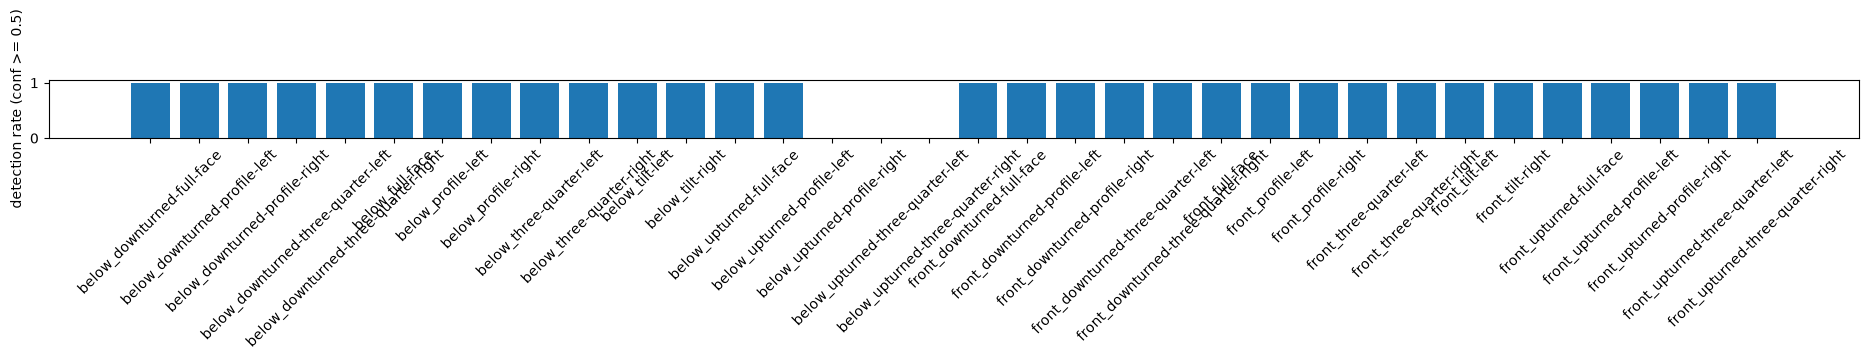

In [9]:
display(plots.detection_rate(out, threshold=DET_THRESHOLD).to_frame())
plots.plot_detection_rate(out, threshold=DET_THRESHOLD);

### Speed (fps on this machine)

Includes video decoding and face detection. Note the hardware (CPU/GPU) in the verdict.

In [10]:
plots.fps_table(timings, out)

,n_frames,seconds,fps
below_downturned-full-face,1,0.042653,23.444982
below_downturned-profile-left,1,0.044020,22.717058
below_downturned-profile-right,1,0.042059,23.776255
below_downturned-three-quarter-left,1,0.042869,23.327024
below_downturned-three-quarter-right,1,0.043576,22.948364
below_full-face,1,0.042701,23.418628
below_profile-left,1,0.044140,22.655286
below_profile-right,1,0.040954,24.417504
below_three-quarter-left,1,0.041338,24.190638
below_three-quarter-right,1,0.041438,24.132544


### Per-clip summary

One row per clip with mean outputs over detected frames, next to the manifest's head-pose labels. `yaw_error_deg` compares `pose_yaw_deg` with the manifest's rough `approx_head_yaw_deg` (0, ±45, ±90), so treat it as a sanity check, not accuracy.

In [11]:
detected = out[out['face_conf'] >= DET_THRESHOLD]
summary = detected.groupby('clip_id').agg(
    n_frames=('frame', 'size'), face_conf=('face_conf', 'mean'),
    pose_yaw_deg=('pose_yaw_deg', 'mean'), pose_pitch_deg=('pose_pitch_deg', 'mean'), pose_roll_deg=('pose_roll_deg', 'mean'),
)
labels = manifest.set_index('clip_id').drop(columns=['path', 'test_set']).dropna(axis=1, how='all')  # skip label columns unused by these categories
summary = labels.join(summary, how='left')
summary['yaw_error_deg'] = summary['pose_yaw_deg'] - summary['approx_head_yaw_deg']
summary.round(1)

,category,camera,head_yaw,head_pitch,head_roll,approx_head_yaw_deg,n_frames,face_conf,pose_yaw_deg,pose_pitch_deg,pose_roll_deg,yaw_error_deg
clip_id,,,,,,,,,,,,
front_full-face,head_pose,front,full-face,level,none,0.0,1.0,0.9,0.1,-8.8,1.3,0.1
front_three-quarter-left,head_pose,front,three-quarter-left,level,none,45.0,1.0,0.9,37.8,-4.3,0.9,-7.2
front_three-quarter-right,head_pose,front,three-quarter-right,level,none,-45.0,1.0,0.9,-46.4,-6.4,-6.9,-1.4
front_profile-left,head_pose,front,profile-left,level,none,90.0,1.0,0.9,76.4,2.9,1.1,-13.6
front_profile-right,head_pose,front,profile-right,level,none,-90.0,1.0,0.9,-75.3,-8.4,-12.9,14.7
front_upturned-full-face,head_pose,front,full-face,upturned,none,0.0,1.0,0.9,-1.4,32.4,-0.7,-1.4
front_upturned-three-quarter-left,head_pose,front,three-quarter-left,upturned,none,45.0,1.0,0.9,18.8,31.0,-11.3,-26.2
front_upturned-three-quarter-right,head_pose,front,three-quarter-right,upturned,none,-45.0,1.0,0.9,-22.2,36.4,11.0,22.8
front_upturned-profile-left,head_pose,front,profile-left,upturned,none,90.0,1.0,0.9,41.2,42.7,-32.4,-48.8


In [12]:
# Mean pose per label, separately for each camera (NaN = no detection)
for col in ['head_yaw', 'head_pitch', 'head_roll']:
    display(summary.pivot_table(index=col, columns='camera', values=['pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg'], aggfunc='mean').round(1))

pose_pitch_deg       pose_roll_deg       pose_yaw_deg  \
camera                       below front         below front        below   
head_yaw                                                                    
full-face                     -4.0  -2.2         -19.6  -0.1        -15.6   
profile-left                  17.4   0.8           3.6   1.7         55.2   
profile-right                 16.8  -0.3         -11.6  -8.4        -64.8   
three-quarter-left             5.0  -1.8           6.8   0.7         32.0   
three-quarter-right           10.4   0.2          -7.5  -3.0        -33.6   

                           
camera              front  
head_yaw                   
full-face            -1.1  
profile-left         59.5  
profile-right       -62.3  
three-quarter-left   29.7  
three-quarter-right -31.3

pose_pitch_deg       pose_roll_deg       pose_yaw_deg      
camera              below front         below front        below front
head_pitch                                                            
downturned          -10.7 -34.8           0.2   0.2         -1.7   1.5
level                30.5  -4.1           0.0  -2.7          2.1  -1.9
upturned            -31.6  37.7         -56.4  -1.9        -26.0  -2.5

pose_pitch_deg       pose_roll_deg       pose_yaw_deg      
camera              below front         below front        below front
head_roll                                                             
none                  2.4  -0.7          -9.1  -1.7         -4.3  -0.9
tilt-left            37.2   1.1          27.5  27.2          2.6  -0.7
tilt-right           31.0  -4.6         -29.3 -30.0          3.5  -5.0

### Detections on single-image clips

Top face box and confidence on each image, one grid per manifest category, with the predicted head pose drawn from the schema columns (so it also checks the sign conversion): the blue arrow is where the face points (yaw, pitch), the orange line is the tilt (roll).

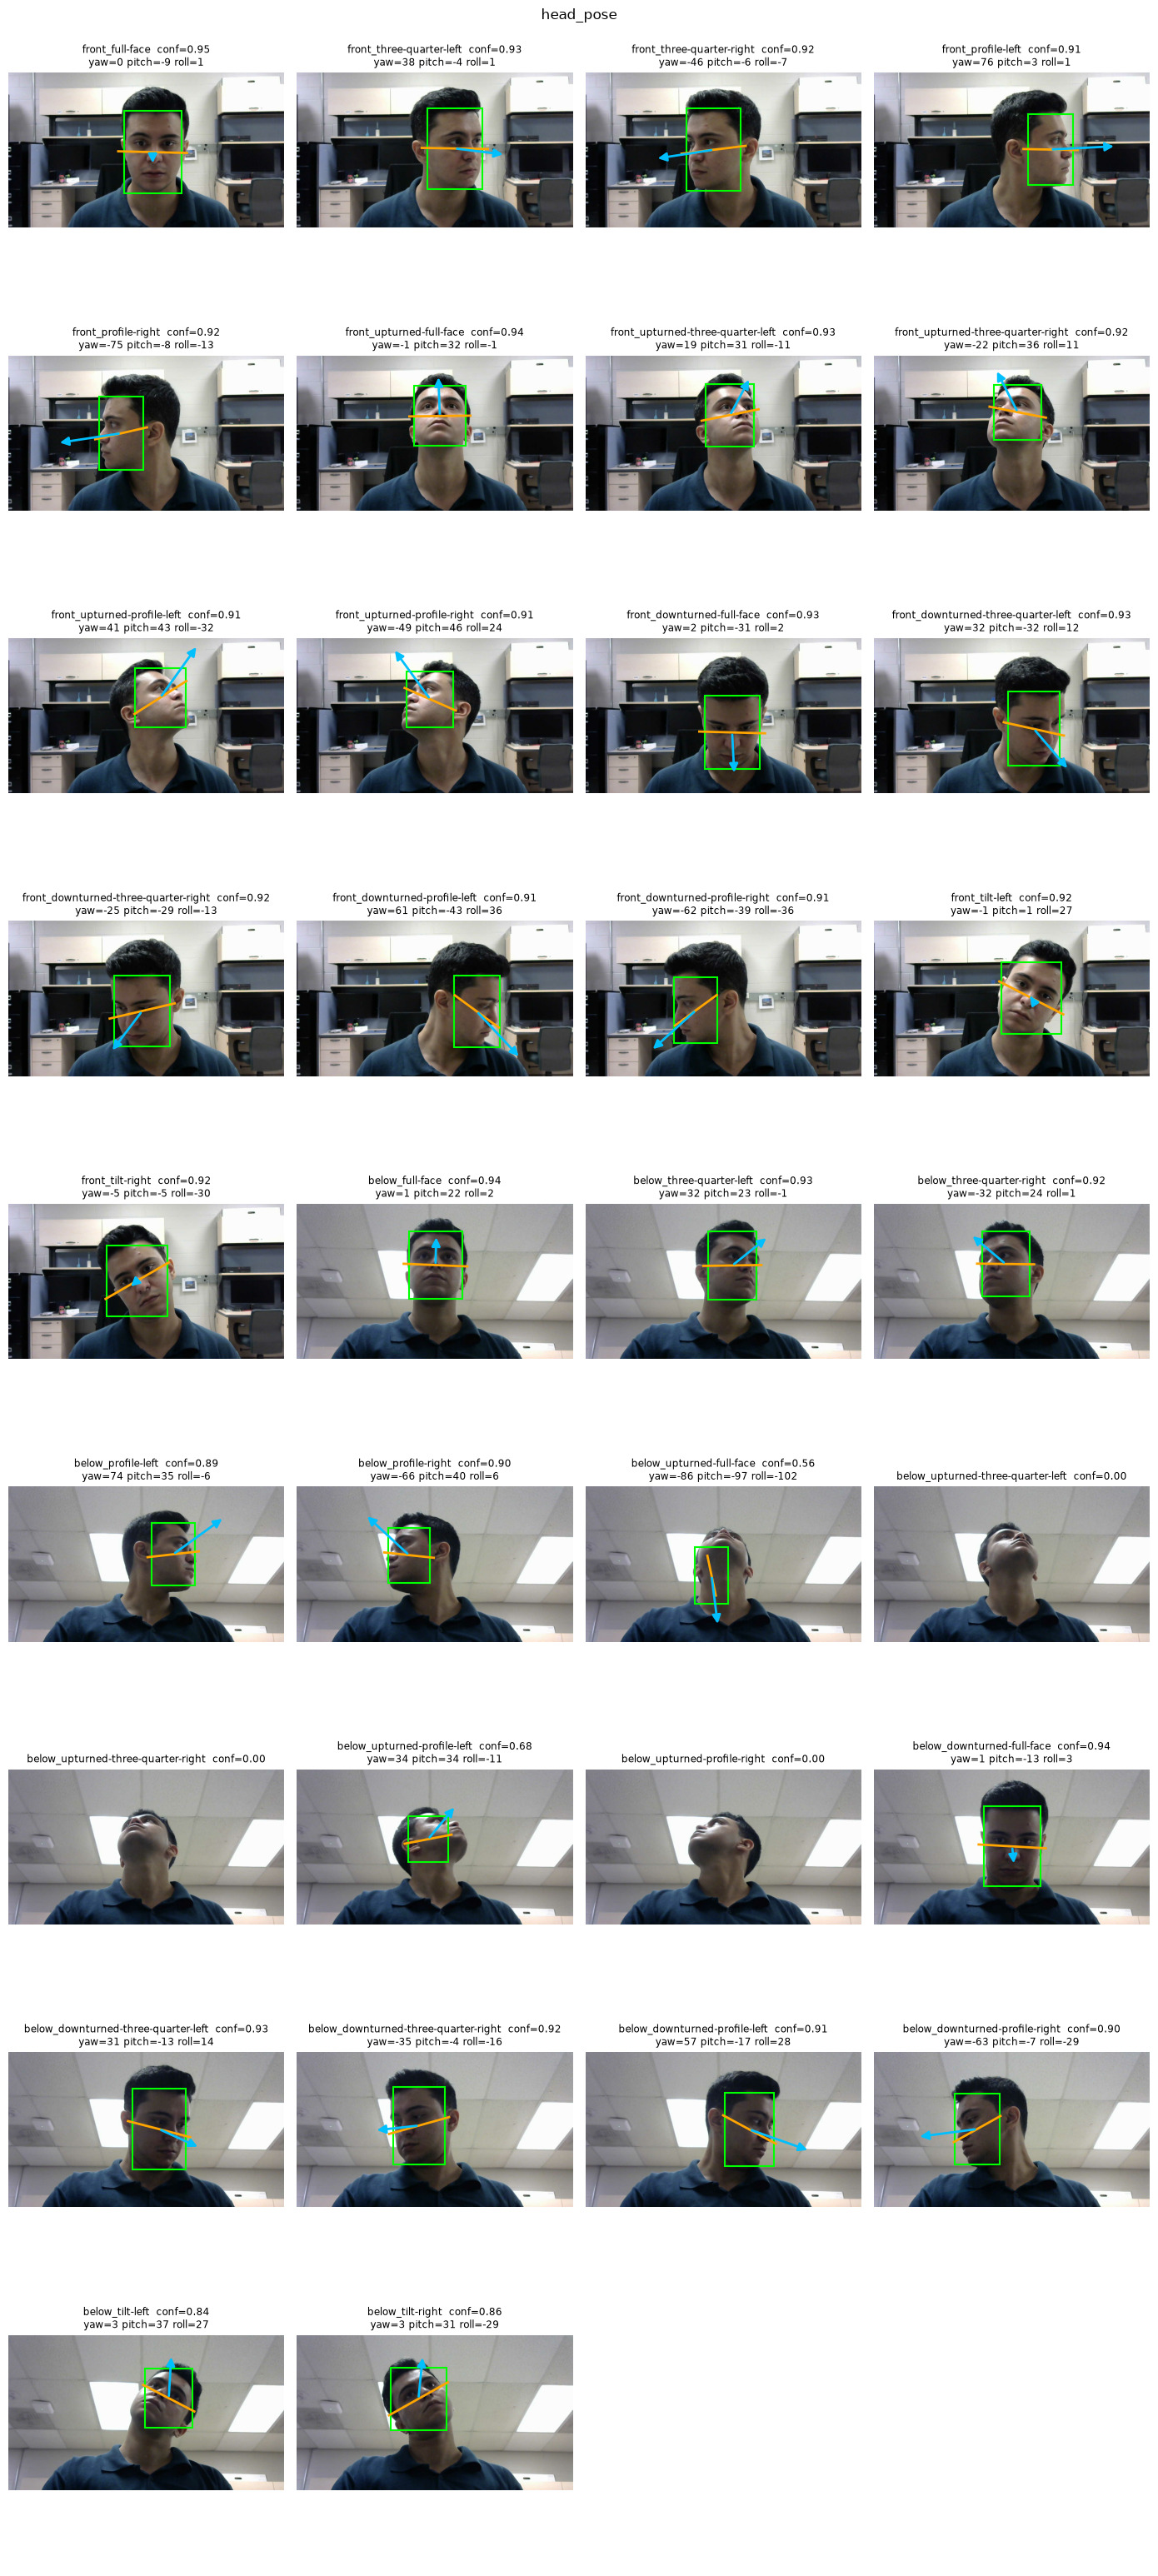

In [13]:
def draw_pose(ax, r):
    """Face-direction arrow (yaw, pitch) and a roll line, from the schema columns.
    Assumes a true-orientation image: the subject's left is the image's right."""
    if pd.isna(r['pose_yaw_deg']):
        return
    x1, y1, x2, y2 = r[['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']]
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    size = x2 - x1
    yaw, pitch, roll = np.radians(r[['pose_yaw_deg', 'pose_pitch_deg', 'pose_roll_deg']].astype(float))
    dx = 1.5 * size * np.sin(yaw) * np.cos(pitch)  # positive yaw (subject's left) -> image right
    dy = -1.5 * size * np.sin(pitch)               # positive pitch (up) -> image up
    ax.annotate('', xy=(cx + dx, cy + dy), xytext=(cx, cy),
                arrowprops=dict(arrowstyle='-|>', color='deepskyblue', lw=2, mutation_scale=15))
    # Roll: positive (toward the subject's left shoulder = image right) turns the line clockwise on screen
    lx, ly = 0.6 * size * np.cos(roll), 0.6 * size * np.sin(roll)
    ax.plot([cx - lx, cx + lx], [cy - ly, cy + ly], color='orange', lw=2)


groups = manifest.groupby('category', sort=False) if 'category' in manifest else [('all clips', manifest)]
for category, rows in groups:
    still = [r for r in rows.itertuples() if clip_io.is_image(clip_io.clip_path(r))]
    if not still:
        continue
    ncols = 4
    fig, axes = plt.subplots(-(-len(still) // ncols), ncols, figsize=(3.5 * ncols, 3.5 * -(-len(still) // ncols)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, row in zip(axes.flat, still):
        _, _, img = next(clip_io.iter_frames(clip_io.clip_path(row), rgb=True))
        r = out[out['clip_id'] == row.clip_id].iloc[0]
        ax.imshow(img)
        title = f"{row.clip_id}  conf={r['face_conf']:.2f}"
        if r['face_conf'] >= DET_THRESHOLD:
            x1, y1, x2, y2 = r[['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']]
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='lime', lw=1.5))
            draw_pose(ax, r)
            title += f"\nyaw={r['pose_yaw_deg']:.0f} pitch={r['pose_pitch_deg']:.0f} roll={r['pose_roll_deg']:.0f}"
        ax.set_title(title, fontsize='small')
    fig.suptitle(category)
    plt.tight_layout()
    plt.show()

### Standard plots per clip

Video clips only (time series need more than one frame).

In [14]:
for clip_id, df in out.groupby('clip_id'):
    if len(df) < 2:
        continue
    plots.plot_face_conf(df)
    plots.plot_pose(df)
    plt.show()

### Plausibility and stability (no ground truth)

- Value ranges: do the angles look reasonable for what happens in each clip?
- Jitter: median absolute frame-to-frame change on detected frames. A high value on a still face means a noisy model.

In [15]:
angle_cols = [c for c in schema.POSE_COLUMNS if c in out]
display(detected[angle_cols].describe().T.round(3))

# Jitter needs consecutive frames, so only video clips count
multi = detected.groupby('clip_id').filter(lambda d: len(d) > 1)
if len(multi):
    jitter = multi.groupby('clip_id')[angle_cols].apply(lambda d: d.diff().abs().median())
    display(jitter.rename(columns=lambda c: c.replace('_deg', '_jitter_deg')))
else:
    print('no multi-frame clips yet: jitter skipped')

,count,mean,std,min,25%,50%,75%,max
pose_yaw_deg,31.0,-2.066,44.464,-86.081,-33.585,0.647,32.454,76.351
pose_pitch_deg,31.0,2.666,32.459,-97.165,-13.273,-3.591,31.719,46.181
pose_roll_deg,31.0,-4.499,26.053,-101.869,-13.012,0.663,8.580,36.207


no multi-frame clips yet: jitter skipped


### Failure cases

Frames where the face was missed or detected with low confidence. Look at a few to see why (pose, occlusion, lighting, blur).

In [16]:
failures = plots.failure_frames(out, threshold=DET_THRESHOLD)
display(failures.groupby('clip_id').size().rename('n_failures').to_frame())
failures.head(20)

,n_failures
clip_id,
below_upturned-profile-right,1
below_upturned-three-quarter-left,1
below_upturned-three-quarter-right,1


,clip_id,frame,timestamp_ms,face_conf
14,below_upturned-profile-right,0,0.0,0.0
15,below_upturned-three-quarter-left,0,0.0,0.0
16,below_upturned-three-quarter-right,0,0.0,0.0


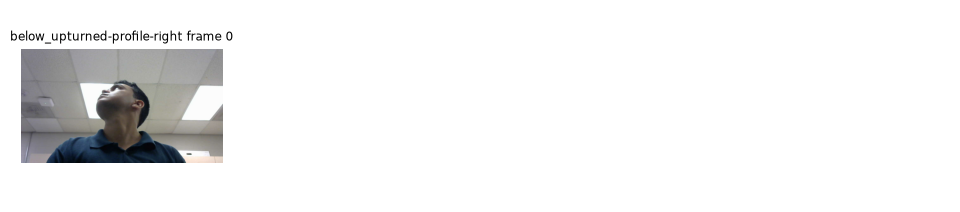

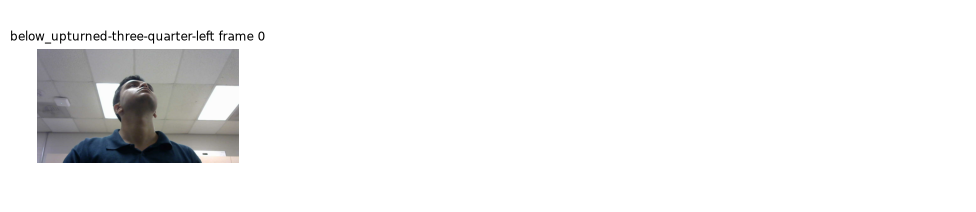

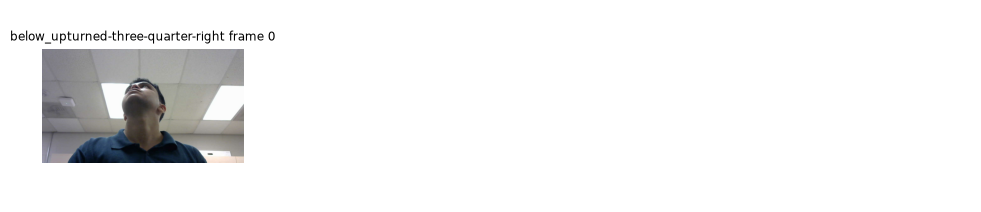

In [17]:
def show_frames(clip_id, frames, ncols=4):
    row = manifest.set_index('clip_id').loc[clip_id]
    wanted = set(frames)
    images = [(f, img) for f, _, img in clip_io.iter_frames(clip_io.clip_path(row), rgb=True) if f in wanted]
    if not images:
        return
    nrows = -(-len(images) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2.5 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, (f, img) in zip(axes.flat, images):
        ax.imshow(img)
        ax.set_title(f'{clip_id} frame {f}', fontsize='small')
    plt.show()

# Up to 8 evenly spaced failure frames per clip
for clip_id, f in failures.groupby('clip_id'):
    show_frames(clip_id, f['frame'].iloc[np.linspace(0, len(f) - 1, min(8, len(f))).astype(int)])